# Juneau Icefield radar: 2021 data exploration

## Getting started

- **Kernel:** select **JIF snow modeling** (`jif_snow_modeling`).
- **Run order:** execute the cells from top to bottom.
- **Source CSV:** `/hdd/snow_hydrology/JIF_radar/ml_swe_2021.csv`.
- **Data documentation:** `readme_jif_ml_data.docx` in the same folder, compiled 18 September 2026.

## What this notebook does

1. Opens the CSV and describes its columns, units, and profiles.
2. Checks missing values, duplicates, and consistency between units.
3. Maps all points with finite coordinates by profile and SWE.
4. Explores measurement distributions and relationships with elevation.

**Data handling:** the source CSV is unchanged. Rows are not sampled or deduplicated; each plot identifies which values it can display.

> **Coordinate reference:** the documentation specifies **UTM Zone 8N, metres**, but does not identify the datum. Maps use the supplied projected coordinates without assuming an EPSG code, geographic transformation, or basemap.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('/hdd/snow_hydrology/JIF_radar')
CSV_PATH = DATA_DIR / 'ml_swe_2021.csv'
# Support launching from the repo root or radar/.
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / 'radar' / '01_explore_radar_2021.ipynb').is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError('Launch this notebook from the repository root or radar/.')
FIGURE_DIR = REPO_ROOT / 'radar' / 'figures'
SAVE_FIGURES = True  # Generated PNGs are ignored by Git.
if SAVE_FIGURES:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(fig, filename):
    if SAVE_FIGURES:
        fig.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()

print('Python:', sys.executable)
print('Source:', CSV_PATH)
if not CSV_PATH.is_file():
    raise FileNotFoundError(f'Update DATA_DIR or provide the external radar dataset: {CSV_PATH}')
df = pd.read_csv(CSV_PATH, encoding='utf-8-sig')
print(f'{len(df):,} rows; {len(df.columns)} columns; {df["profile"].nunique():,} profiles')
display(df.head())

Python: /home/cassie/programs/miniforge3/envs/jif_snow_modeling/bin/python
Source: /hdd/snow_hydrology/JIF_radar/ml_swe_2021.csv
119,218 rows; 10 columns; 9 profiles


,profile,east,north,twtt1,aa_avg_depth_m,aa_avg_depth_cm,aa_swe_avg_m,aa_swe_avg_cm_we,coast_dist_m,elev_dem_m
0,NWBN,526958.3095,6500548.944,74.888,5.952329,595.232937,3.340390,334.038972,21209.44531,1564.5
1,NWBN,526957.6527,6500547.882,74.888,5.952329,595.232937,3.340390,334.038972,21209.44531,1564.5
2,NWBN,526956.9959,6500546.819,74.888,5.952329,595.232937,3.340390,334.038972,21209.44531,1564.5
3,NWBN,526956.3391,6500545.757,74.888,5.952329,595.232937,3.340390,334.038972,21209.44531,1564.5
4,NWBN,526955.6824,6500544.695,74.717,5.938738,593.873777,3.332451,333.245073,21209.44531,1564.5


## Columns and units

### How the measurements were derived

- **Snow depth:** calculated using an average relative permittivity for each year.
- **Snow water equivalent (SWE):** calculated from depth using a prescribed snow density for each year.
- **Interpretation:** depth and SWE should not be treated as independent measurements.

### Details to check

- **Travel time (`twtt1`):** the documentation does not state its time unit.
- **Missing data:** no numeric missing-data sentinel is documented.
- **Profile labels:** compiled across multiple projects; they do not necessarily correspond one-to-one to glacier branches.

### CSV names versus documentation

Use the **actual CSV column names** in the code:

| CSV column | Name in the documentation |
| --- | --- |
| `aa_swe_avg_cm_we` | `aa_swe_avg_cm` |
| `coast_dist_m` | `coast_dist` |

The next cell lists column descriptions, data types, and summary statistics.

In [2]:
column_notes = {
    'profile': 'Source profile/branch label (compiled across projects)',
    'east': 'Easting, UTM Zone 8N (m); datum unconfirmed',
    'north': 'Northing, UTM Zone 8N (m); datum unconfirmed',
    'twtt1': 'Two-way travel time; unit not stated in readme',
    'aa_avg_depth_m': 'Snow depth (m)',
    'aa_avg_depth_cm': 'Snow depth (cm)',
    'aa_swe_avg_m': 'SWE (m water equivalent)',
    'aa_swe_avg_cm_we': 'SWE (cm water equivalent)',
    'coast_dist_m': 'Distance from Lynn Channel coastline delineation (m)',
    'elev_dem_m': 'Elevation from Polar Geospatial Center DEM (m)',
}
missing_columns = set(column_notes) - set(df.columns)
if missing_columns:
    raise ValueError(f'Missing expected columns: {sorted(missing_columns)}')
display(pd.DataFrame({'description': pd.Series(column_notes),
                      'dtype': df.dtypes.astype(str)}))
display(df.describe(include='all').T)

,description,dtype
profile,Source profile/branch label (compiled across p...,object
east,"Easting, UTM Zone 8N (m); datum unconfirmed",float64
north,"Northing, UTM Zone 8N (m); datum unconfirmed",float64
twtt1,Two-way travel time; unit not stated in readme,float64
aa_avg_depth_m,Snow depth (m),float64
aa_avg_depth_cm,Snow depth (cm),float64
aa_swe_avg_m,SWE (m water equivalent),float64
aa_swe_avg_cm_we,SWE (cm water equivalent),float64
coast_dist_m,Distance from Lynn Channel coastline delineati...,float64
elev_dem_m,Elevation from Polar Geospatial Center DEM (m),float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
profile,119218,9,Matthes-Taku,26537,NaN,NaN,NaN,NaN,NaN,NaN,NaN
east,119218.0,NaN,NaN,NaN,541883.991055,9162.46011,522783.7807,535207.3359,541598.8726,546483.631,565159.4375
north,119218.0,NaN,NaN,NaN,6502533.270482,7314.276551,6484862.622,6498189.212,6501871.2105,6506454.474,6521891.199
twtt1,111801.0,NaN,NaN,NaN,44.49095,17.781479,3.965,33.428,40.366,50.273,126.67
aa_avg_depth_m,111801.0,NaN,NaN,NaN,3.536278,1.413327,0.31515,2.656961,3.208414,3.995853,10.068123
aa_avg_depth_cm,111801.0,NaN,NaN,NaN,353.627806,141.332686,31.515044,265.696061,320.841427,399.58532,1006.812255
aa_swe_avg_m,119218.0,NaN,NaN,NaN,1.827406,0.919077,0.0,1.34762,1.69376,2.172762,5.772877
aa_swe_avg_cm_we,111801.0,NaN,NaN,NaN,194.863763,81.517003,15.683592,144.268481,175.560128,220.618828,577.287683
coast_dist_m,119218.0,NaN,NaN,NaN,33483.020274,8019.622711,17105.25781,26586.85938,34170.89063,37712.85938,55442.47266
elev_dem_m,119218.0,NaN,NaN,NaN,1314.758626,195.031321,980.265625,1134.640625,1314.132813,1473.984375,1822.617188


## Data quality and profile coverage

### Checks performed below

- **Missing values:** count and percentage for each column.
- **Non-finite values:** infinite numeric values and unusable coordinate pairs.
- **Duplicates:** exact duplicate rows and repeated coordinate pairs, reported separately.
- **Measurement flags:** numeric SWE values where travel time or depth is missing.
- **Negative values:** counts for numeric columns, for inspection.
- **Profile coverage:** row counts, available depth values, median SWE, and elevation range.

**All original rows are retained**, including duplicates. The code reports potential issues without silently replacing values.

> **Review flag:** numeric SWE alongside missing travel time/depth does not by itself establish a valid observation or justify deleting the row. Investigate these rows before model comparison.

In [3]:
numeric_columns = df.select_dtypes(include=np.number).columns
quality = pd.DataFrame({
    'missing': df.isna().sum(),
    'missing_percent': 100 * df.isna().mean(),
    'unique_nonmissing': df.nunique(),
})
quality['infinite'] = pd.Series({c: np.isinf(df[c]).sum() for c in numeric_columns})
display(quality)
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Repeated coordinate pairs:', int(df.duplicated(['east', 'north']).sum()))
coordinate_ok = np.isfinite(df[['east', 'north']]).all(axis=1)
measurement_flag = df['twtt1'].isna() | df['aa_avg_depth_m'].isna()
flagged_swe = measurement_flag & np.isfinite(df['aa_swe_avg_m'])
print('Rows without finite coordinates:', int((~coordinate_ok).sum()))
print('Rows with missing travel time/depth but numeric SWE (m):', int(flagged_swe.sum()))
display(df.loc[flagged_swe].head())
display(pd.DataFrame({'negative_values': (df[numeric_columns] < 0).sum()}))
profile_summary = df.groupby('profile', dropna=False).agg(
    points=('east', 'size'),
    depth_nonmissing=('aa_avg_depth_m', 'count'),
    swe_median_m=('aa_swe_avg_m', 'median'),
    elevation_min_m=('elev_dem_m', 'min'),
    elevation_max_m=('elev_dem_m', 'max'),
).sort_values('points', ascending=False)
display(profile_summary)

Exact duplicate rows: 180
Repeated coordinate pairs: 228
Rows without finite coordinates: 0
Rows with missing travel time/depth but numeric SWE (m): 7417


,missing,missing_percent,unique_nonmissing,infinite
profile,0,0.000000,9,NaN
east,0,0.000000,118675,0.0
north,0,0.000000,111003,0.0
twtt1,7417,6.221376,982,0.0
aa_avg_depth_m,7417,6.221376,982,0.0
aa_avg_depth_cm,7417,6.221376,982,0.0
aa_swe_avg_m,0,0.000000,983,0.0
aa_swe_avg_cm_we,7417,6.221376,982,0.0
coast_dist_m,0,0.000000,534,0.0
elev_dem_m,0,0.000000,15586,0.0


,profile,east,north,twtt1,aa_avg_depth_m,aa_avg_depth_cm,aa_swe_avg_m,aa_swe_avg_cm_we,coast_dist_m,elev_dem_m
4369,NWBN,522786.5358,6499262.933,NaN,NaN,NaN,0.0,NaN,17105.25781,1541.125
4370,NWBN,522785.6174,6499262.602,NaN,NaN,NaN,0.0,NaN,17105.25781,1541.125
4371,NWBN,522784.6991,6499262.271,NaN,NaN,NaN,0.0,NaN,17105.25781,1541.125
4372,NWBN,522783.7807,6499261.940,NaN,NaN,NaN,0.0,NaN,17105.25781,1541.125
4373,NWBN,522783.7807,6499261.940,NaN,NaN,NaN,0.0,NaN,17105.25781,1541.125


,negative_values
east,0
north,0
twtt1,0
aa_avg_depth_m,0
aa_avg_depth_cm,0
aa_swe_avg_m,0
aa_swe_avg_cm_we,0
coast_dist_m,0
elev_dem_m,0


,points,depth_nonmissing,swe_median_m,elevation_min_m,elevation_max_m
profile,,,,,
Matthes-Taku,26537,25516,1.601142,980.265625,1822.617188
DEMOREST,20654,17632,1.278560,980.320312,1345.164063
SWB,19033,15701,2.052513,1039.851563,1265.546875
NWBS,18997,18988,2.558781,1201.664063,1601.367188
NWBN,15261,15253,2.268940,1339.601563,1577.375000
ECHO_R,7975,7969,1.355237,1268.023438,1520.695313
ECHO_C,5414,5407,0.861545,1277.437500,1333.507813
CS_ECHO_R,3077,3073,1.385902,1412.421875,1520.281250
CS_NWBN,2270,2262,2.394096,1543.656250,1568.203125


### Unit consistency

The next cell compares paired measurements:

- **Depth:** `aa_avg_depth_m × 100` versus `aa_avg_depth_cm`.
- **SWE:** `aa_swe_avg_m × 100` versus `aa_swe_avg_cm_we`.

For each pair, it reports:

- The number of rows with both values, and the number without a complete pair.
- The largest absolute difference in centimetres.
- The number of differences exceeding **0.001 cm**, a small rounding tolerance.

**Neither column is replaced.** Agreement is checked only where both values are finite.

In [4]:
unit_checks = []
for metres, centimetres in [('aa_avg_depth_m', 'aa_avg_depth_cm'),
                            ('aa_swe_avg_m', 'aa_swe_avg_cm_we')]:
    paired = np.isfinite(df[[metres, centimetres]]).all(axis=1)
    difference = (df.loc[paired, metres] * 100 - df.loc[paired, centimetres]).abs()
    unit_checks.append({'pair': f'{metres} × 100 vs {centimetres}',
                        'paired_rows': int(paired.sum()),
                        'unpaired_rows': int((~paired).sum()),
                        'max_absolute_difference_cm': difference.max(),
                        'rows_differing_over_0.001_cm': int((difference > 0.001).sum())})
display(pd.DataFrame(unit_checks))

,pair,paired_rows,unpaired_rows,max_absolute_difference_cm,rows_differing_over_0.001_cm
0,aa_avg_depth_m × 100 vs aa_avg_depth_cm,111801,7417,4.917447e-08,0
1,aa_swe_avg_m × 100 vs aa_swe_avg_cm_we,111801,7417,4.992629e-08,0


## Projected point maps

### Reading the two panels

| Panel | What it shows |
| --- | --- |
| **Profile map** | Every finite-coordinate row, coloured by its source profile label |
| **SWE map** | Numeric SWE values as supplied, with grey locations underneath for context |
| **Orange outlines** | Rows with numeric SWE but missing travel time or depth |

### Mapping choices

- **No sampling:** every row with finite coordinates is plotted, including rows missing a measurement.
- **No cleaning:** flagged SWE values are retained and identified explicitly.
- **Equal axis scaling:** preserves spatial proportions in the supplied UTM coordinates.
- **Overlapping points:** multiple rows can occupy the same visible location at this scale.

> **CRS limitation:** axes are UTM Zone 8N eastings/northings in metres. Confirm the datum before adding a geographic basemap or transforming coordinates.

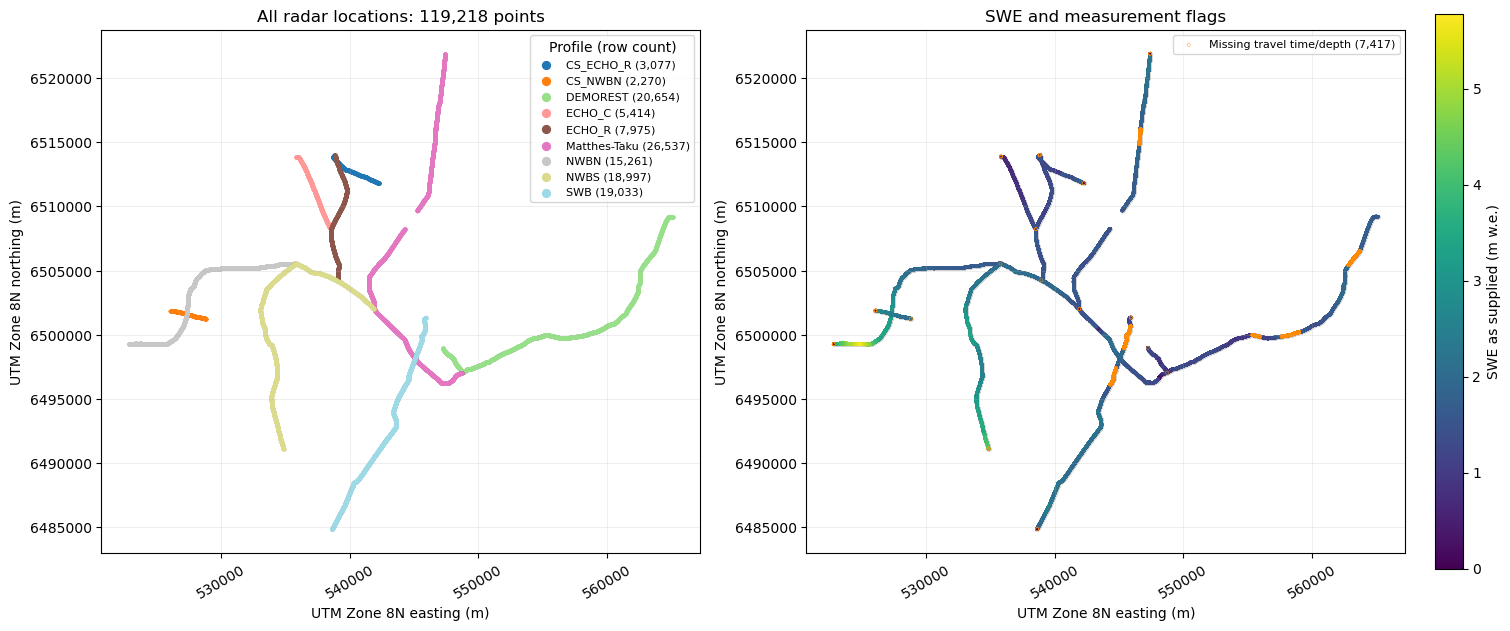

In [5]:
points = df.loc[coordinate_ok].copy()
if points.empty:
    raise ValueError('No finite coordinate pairs to map.')
fig, axes = plt.subplots(1, 2, figsize=(15, 8), constrained_layout=True)
profiles = sorted(points['profile'].dropna().unique())
colours = plt.get_cmap('tab20', max(len(profiles), 1))
for i, profile in enumerate(profiles):
    subset = points.loc[points['profile'].eq(profile)]
    axes[0].scatter(subset['east'], subset['north'], s=2, color=colours(i),
                    label=f'{profile} ({len(subset):,})', rasterized=True)
unknown = points['profile'].isna()
if unknown.any():
    axes[0].scatter(points.loc[unknown, 'east'], points.loc[unknown, 'north'],
                    s=2, color='gray', label='Missing profile', rasterized=True)
axes[0].set_title(f'All radar locations: {len(points):,} points')
axes[0].legend(title='Profile (row count)', markerscale=4, fontsize=8)
axes[1].scatter(points['east'], points['north'], s=2, color='lightgray', rasterized=True)
swe_ok = np.isfinite(points['aa_swe_avg_m'])
if swe_ok.any():
    scatter = axes[1].scatter(points.loc[swe_ok, 'east'], points.loc[swe_ok, 'north'],
                              c=points.loc[swe_ok, 'aa_swe_avg_m'], s=2,
                              cmap='viridis', rasterized=True)
    fig.colorbar(scatter, ax=axes[1], label='SWE as supplied (m w.e.)', shrink=0.7)
flagged = points.index.intersection(df.index[flagged_swe])
axes[1].scatter(points.loc[flagged, 'east'], points.loc[flagged, 'north'], s=5,
                facecolors='none', edgecolors='darkorange', linewidths=0.3,
                label=f'Missing travel time/depth ({len(flagged):,})', rasterized=True)
axes[1].legend(fontsize=8)
axes[1].set_title('SWE and measurement flags')
for ax in axes:
    ax.set(xlabel='UTM Zone 8N easting (m)', ylabel='UTM Zone 8N northing (m)')
    ax.set_aspect('equal', adjustable='box')
    ax.ticklabel_format(style='plain', useOffset=False)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=0.2)
finish_figure(fig, 'radar_2021_point_maps.png')

## Radar extent on a basemap

### What the basemap adds

- **Geographic context:** Natural Earth land, ocean, coastlines, and lakes at 1:10 million scale.
- **Same radar points:** all finite-coordinate rows, coloured by profile (left) and SWE (right).
- **Wider extent:** a 30 km margin around the radar footprint shows the surrounding coast and inland setting.
- **Measurement flags:** orange outlines retain the missing travel time/depth warning on the SWE panel.

> **Provisional datum assumption:** the data documentation gives UTM Zone 8N but no datum. For this contextual map only, `RADAR_EPSG = 32608` assumes **WGS 84 / UTM Zone 8N**. Confirm the datum before using this overlay for spatial matching or quantitative analysis. The preceding projected map does not require that assumption.

### Basemap data and output

- **Source:** Natural Earth via Cartopy; no API key or imagery service is needed.
- **Cache:** Cartopy uses its local data cache and downloads missing shapefiles on first use. A download requires internet access and a writable cache directory.
- **Output:** `radar/figures/radar_2021_point_maps_basemap.png` when `SAVE_FIGURES` is true.
- **Limit:** coastlines and lakes provide context, not glacier boundaries or terrain relief.

Assumed radar CRS: WGS 84 / UTM zone 8N
Confirm the source datum before quantitative spatial comparison.


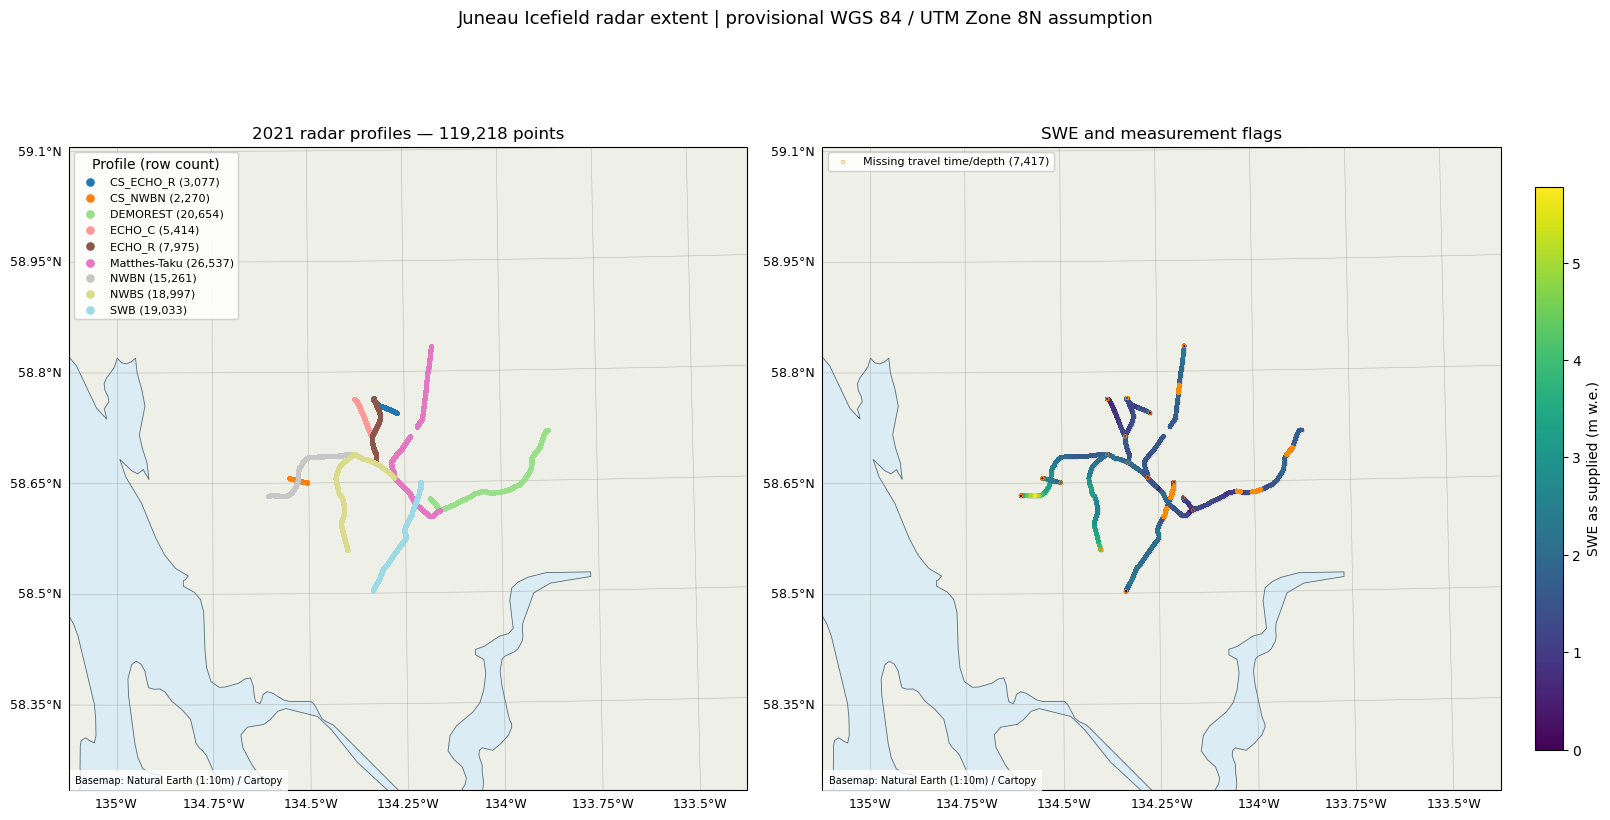

In [6]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pyproj import CRS

# Provisional visualization assumption; update only after confirming the datum.
RADAR_EPSG = 32608
radar_crs = ccrs.epsg(RADAR_EPSG)
print('Assumed radar CRS:', CRS.from_epsg(RADAR_EPSG).name)
print('Confirm the source datum before quantitative spatial comparison.')

MAP_MARGIN_M = 30_000
xmin, xmax = points['east'].min() - MAP_MARGIN_M, points['east'].max() + MAP_MARGIN_M
ymin, ymax = points['north'].min() - MAP_MARGIN_M, points['north'].max() + MAP_MARGIN_M
fig, axes = plt.subplots(1, 2, figsize=(16, 9),
                         subplot_kw={'projection': radar_crs}, constrained_layout=True)
for ax in axes:
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.add_feature(cfeature.OCEAN.with_scale('10m'), facecolor='#dcecf4', zorder=0)
    ax.add_feature(cfeature.LAND.with_scale('10m'), facecolor='#eef0e7', zorder=0)
    ax.add_feature(cfeature.LAKES.with_scale('10m'), facecolor='#c1dce9',
                   edgecolor='#8bb2c5', linewidth=0.3, zorder=1)
    ax.coastlines(resolution='10m', color='#526879', linewidth=0.6, zorder=2)
    grid = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray', alpha=0.5)
    grid.top_labels = False
    grid.right_labels = False
    grid.xlabel_style = {'size': 9}
    grid.ylabel_style = {'size': 9}

for i, profile in enumerate(profiles):
    subset = points.loc[points['profile'].eq(profile)]
    axes[0].scatter(subset['east'], subset['north'], transform=radar_crs,
                    s=3, color=colours(i), label=f'{profile} ({len(subset):,})',
                    rasterized=True, zorder=3)
if unknown.any():
    axes[0].scatter(points.loc[unknown, 'east'], points.loc[unknown, 'north'],
                    transform=radar_crs, s=3, color='gray', label='Missing profile',
                    rasterized=True, zorder=3)
axes[0].set_title(f'2021 radar profiles — {len(points):,} points')
axes[0].legend(loc='upper left', title='Profile (row count)',
                fontsize=8, markerscale=3, framealpha=0.9)
axes[1].scatter(points['east'], points['north'], transform=radar_crs,
                s=3, color='lightgray', rasterized=True, zorder=3)
if swe_ok.any():
    scatter = axes[1].scatter(points.loc[swe_ok, 'east'], points.loc[swe_ok, 'north'],
                              transform=radar_crs, c=points.loc[swe_ok, 'aa_swe_avg_m'],
                              s=3, cmap='viridis', rasterized=True, zorder=4)
    fig.colorbar(scatter, ax=axes[1], label='SWE as supplied (m w.e.)', shrink=0.65)
axes[1].scatter(points.loc[flagged, 'east'], points.loc[flagged, 'north'],
                transform=radar_crs, s=6, facecolors='none', edgecolors='darkorange',
                linewidths=0.35, rasterized=True, zorder=5,
                label=f'Missing travel time/depth ({len(flagged):,})')
axes[1].legend(loc='upper left', fontsize=8, framealpha=0.9)
axes[1].set_title('SWE and measurement flags')
fig.suptitle('Juneau Icefield radar extent | provisional WGS 84 / UTM Zone 8N assumption',
             fontsize=13)
for ax in axes:
    ax.text(0.01, 0.01, 'Basemap: Natural Earth (1:10m) / Cartopy',
            transform=ax.transAxes, fontsize=7, zorder=6,
            bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'})
finish_figure(fig, 'radar_2021_point_maps_basemap.png')

## Distributions and elevation relationships

### Plots produced below

- **Histograms:** snow depth, SWE as supplied, and DEM elevation.
- **Elevation relationships:** depth and SWE versus elevation, using hexagonal bins.
- **Hexbin colour:** row count per bin on a logarithmic colour scale.

### How to interpret them

- Each plot uses finite values for its own required columns.
- Duplicate rows and flagged numeric measurements remain included.
- These summaries do **not** correct for spatial sampling density.
- They are exploratory views of the supplied data, rather than evidence of independent validation measurements.

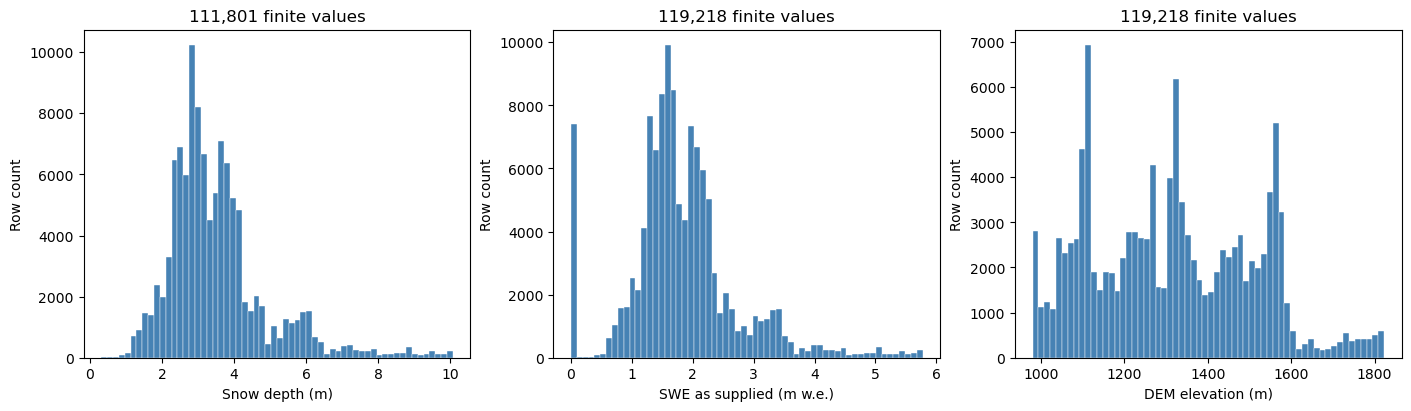

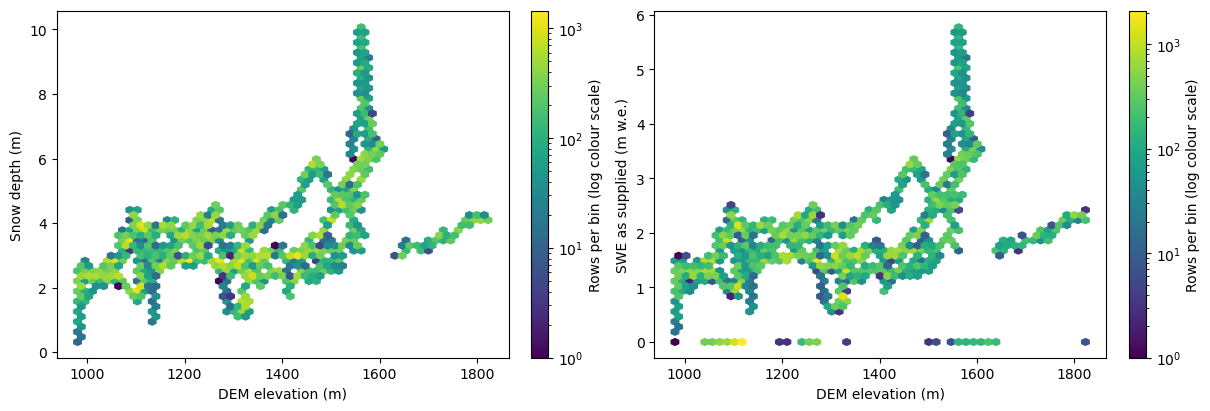

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, column, label in zip(axes,
        ['aa_avg_depth_m', 'aa_swe_avg_m', 'elev_dem_m'],
        ['Snow depth (m)', 'SWE as supplied (m w.e.)', 'DEM elevation (m)']):
    values = df.loc[np.isfinite(df[column]), column]
    ax.hist(values, bins=60, color='steelblue', edgecolor='white', linewidth=0.3)
    ax.set(xlabel=label, ylabel='Row count', title=f'{len(values):,} finite values')
finish_figure(fig, 'radar_2021_distributions.png')

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, column, label in zip(axes, ['aa_avg_depth_m', 'aa_swe_avg_m'],
                             ['Snow depth (m)', 'SWE as supplied (m w.e.)']):
    finite = np.isfinite(df[['elev_dem_m', column]]).all(axis=1)
    if finite.any():
        density = ax.hexbin(df.loc[finite, 'elev_dem_m'], df.loc[finite, column],
                            gridsize=55, mincnt=1, bins='log', cmap='viridis')
        fig.colorbar(density, ax=ax, label='Rows per bin (log colour scale)')
    ax.set(xlabel='DEM elevation (m)', ylabel=label)
finish_figure(fig, 'radar_2021_elevation_relationships.png')

## Before comparing with simulations

Use this checklist to prepare a defensible radar/model comparison:

- [ ] **Coordinate datum:** confirm it before transforming coordinates or overlaying other datasets.
- [ ] **Acquisition dates:** confirm observation timing; the filename identifies 2021, but the CSV has no timestamp column.
- [ ] **Measurement flags:** resolve numeric SWE values on rows missing depth/travel time and review unit discrepancies with the data provider.
- [ ] **Repeated observations:** decide how duplicate rows, repeated locations, and profile labels should be handled for each analysis.
- [ ] **Measurement assumptions:** record prescribed density/permittivity values and measurement uncertainties.
- [ ] **Model matching:** align observation timing and locations with the point simulations before computing errors.

### Saved outputs

- **Location:** `radar/figures/` (ignored by Git).
- **Control:** set `SAVE_FIGURES = True` to save generated plots, or `False` to display them only.
- **Source data:** the original CSV remains unchanged.